# Prototipo funcional mediante transferencia de aprendizaje

En este notebook se desarrollará un modelo capaz de clasificar enfermedades en hojas de tomate mediante transferencia de aprendizaje y fine-tuning  

Se utilizará la arquitectura **ResNet18** preentrenada en ImageNet y el dataset **PlantVillage** que contiene 54.305 imágenes distribuidas en 38 categorías. El experimento se limitará a las 10 clases correspondientes a hojas de tomate, incluyendo hojas sanas y enfermas

**Fuente:** [PlantVillage — Hugging Face](https://huggingface.co/datasets/mohanty/PlantVillage)

El objetivo es implementar y evaluar un pipeline de transferencia de aprendizaje comprendiendo la preparación de datos, el entrenamiento, el fine-tuning y la interpretación de métricas y errores  

## Pipeline experimental

1. **Datos:** selección de las 10 clases de tomate de PlantVillage
2. **Preprocesamiento:** partición Train/Validation/Test, normalización y aumentación
3. **Modelo:** adaptación de ResNet18 para clasificar 10 categorías
4. **Entrenamiento:** ejecución de las configuraciones A y B
5. **Comparación:** análisis de curvas de aprendizaje y métricas de validación
6. **Evaluación final:** Accuracy, Precision, Recall, F1, matriz de confusión y análisis de errores

## Configuración del entorno

In [1]:
import copy
import random
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torchvision

from torch import nn
from torch.utils.data import Dataset, DataLoader

from torchvision import models, transforms
from torchvision.models import ResNet18_Weights

from datasets import load_dataset

from sklearn.model_selection import StratifiedGroupKFold

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

from tqdm.auto import tqdm

In [2]:
SEED = 1010

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

In [3]:
if torch.cuda.is_available():
    device = torch.device("cuda")

elif torch.backends.mps.is_available():
    device = torch.device("mps")

else:
    device = torch.device("cpu")

print("Dispositivo:", device)
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)

Dispositivo: mps
Python: 3.11.16
PyTorch: 2.14.0
TorchVision: 0.29.0


## Exploración y selección del dataset

In [6]:
dataset = load_dataset(
    "geraldmc/plantvillage-full",
    revision="v0.1.0",
    split="train"
)

print(dataset)
print(dataset.features)

README.md:   0%|          | 0.00/549 [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  402MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  453MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/54304 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped'],
    num_rows: 54304
})
{'image': Image(mode=None, decode=True), 'class_label': Value('string'), 'class_idx': Value('int32'), 'host': Value('string'), 'disease': Value('string'), 'split': Value('string'), 'leaf_id': Value('string'), 'leaf_grouped': Value('bool')}


### Selección de las imágenes de tomate

In [ ]:
dataset_tomato = dataset.filter(lambda example: example["host"] == "Tomato")

print("Imágenes de tomate:", len(dataset_tomato))
print("Columnas:", dataset_tomato.column_names)

Filter:   0%|          | 0/54304 [00:00<?, ? examples/s]

Imágenes de tomate: 18160
Columnas: ['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped']


### Identificación de las clases

Como únicamente se utilizará 10 categorías se necesita crear identificadores consecutivos entre 0 y 9

In [8]:
class_pairs = sorted(
    {
        (label, name)
        for label, name in zip(
            dataset_tomato["class_idx"],
            dataset_tomato["class_label"]
        )
    }
)

selected_labels = [label for label, name in class_pairs]
class_names = [name for label, name in class_pairs]

label_mapping = {
    original_label: new_label
    for new_label, original_label
    in enumerate(selected_labels)
}

num_classes = len(class_names)

assert num_classes == 10

for index, name in enumerate(class_names):
    print(index, name)

0 Tomato___Bacterial_spot
1 Tomato___Early_blight
2 Tomato___Late_blight
3 Tomato___Leaf_Mold
4 Tomato___Septoria_leaf_spot
5 Tomato___Spider_mites Two-spotted_spider_mite
6 Tomato___Target_Spot
7 Tomato___Tomato_Yellow_Leaf_Curl_Virus
8 Tomato___Tomato_mosaic_virus
9 Tomato___healthy


### Distribución de las clases

In [9]:
metadata = dataset_tomato.to_pandas()[
    [
        "class_label",
        "class_idx",
        "disease",
        "split",
        "leaf_id",
        "leaf_grouped"
    ]
]

distribution = pd.crosstab(metadata["class_label"], metadata["split"])
distribution["total"] = distribution.sum(axis=1)

display(distribution)

split,test,train,total
class_label,,,
Tomato___Bacterial_spot,424,1703,2127
Tomato___Early_blight,200,800,1000
Tomato___Late_blight,382,1527,1909
Tomato___Leaf_Mold,192,760,952
Tomato___Septoria_leaf_spot,360,1411,1771
Tomato___Spider_mites Two-spotted_spider_mite,336,1340,1676
Tomato___Target_Spot,281,1123,1404
Tomato___Tomato_Yellow_Leaf_Curl_Virus,1069,4288,5357
Tomato___Tomato_mosaic_virus,75,298,373


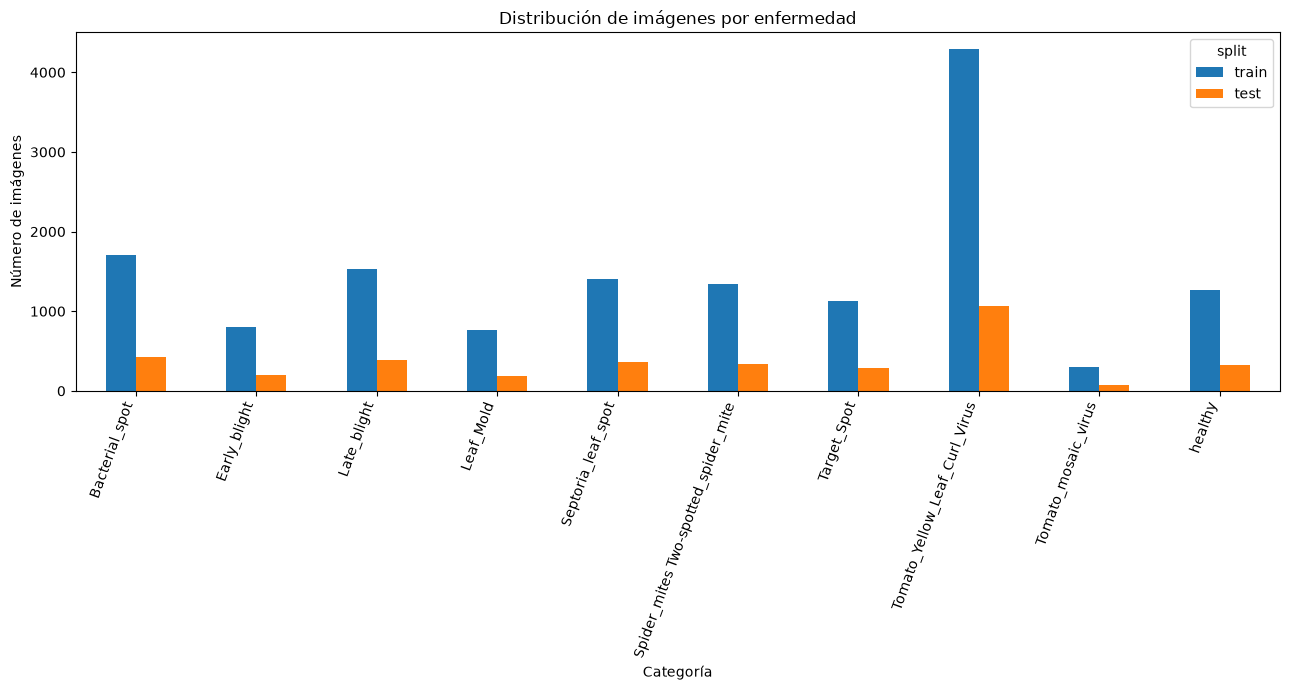

In [67]:
distribution_plot = distribution[["train", "test"]].copy()
distribution_plot.index = distribution_plot.index.str.replace("Tomato___", "", regex=False)

distribution_plot.plot(kind="bar", figsize=(13, 7))

plt.title("Distribución de imágenes por enfermedad")
plt.xlabel("Categoría")
plt.ylabel("Número de imágenes")
plt.xticks(rotation=70, ha="right")
plt.tight_layout()
plt.show()

## Particiones de entrenamiento, validación y prueba

In [11]:
train_pool = dataset_tomato.filter(lambda example: example["split"] == "train")
test_data = dataset_tomato.filter(lambda example: example["split"] == "test")

print("Train original:", len(train_pool))
print("Test:", len(test_data))

Filter:   0%|          | 0/18160 [00:00<?, ? examples/s]

Filter:   0%|          | 0/18160 [00:00<?, ? examples/s]

Train original: 14515
Test: 3645


In [13]:
grouping_coverage = (metadata.groupby("class_label")["leaf_grouped"].agg(["count", "sum"]))
grouping_coverage["grouped_pct"] = (100 * grouping_coverage["sum"] / grouping_coverage["count"])

display(grouping_coverage)

,count,sum,grouped_pct
class_label,,,
Tomato___Bacterial_spot,2127,2127,100.000000
Tomato___Early_blight,1000,999,99.900000
Tomato___Late_blight,1909,920,48.192771
Tomato___Leaf_Mold,952,952,100.000000
Tomato___Septoria_leaf_spot,1771,1000,56.465274
Tomato___Spider_mites Two-spotted_spider_mite,1676,1676,100.000000
Tomato___Target_Spot,1404,0,0.000000
Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357,2738,51.110696
Tomato___Tomato_mosaic_virus,373,0,0.000000


### Crear la partición de validación

In [14]:
labels = np.array(train_pool["class_idx"])
groups = np.array(train_pool["leaf_id"])

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

train_idx, val_idx = next(
    splitter.split(
        X=np.zeros(len(train_pool)),
        y=labels,
        groups=groups
    )
)

train_data = train_pool.select(train_idx)
val_data = train_pool.select(val_idx)

print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))

Train: 11612
Validation: 2903
Test: 3645


### Comprobar la separación

In [15]:
train_groups = set(train_data["leaf_id"])
val_groups = set(val_data["leaf_id"])
test_groups = set(test_data["leaf_id"])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

print("Sin identificadores de hoja compartidos")

Sin identificadores de hoja compartidos


In [17]:
for name, split in [
    ("Train", train_data),
    ("Validation", val_data),
    ("Test", test_data)
]:

    counts = pd.Series(split["class_idx"]).value_counts()
    proportions = (counts / counts.sum()).reindex(selected_labels, fill_value=0)

    print(f"\n{name}")
    print(proportions.round(3))

    assert set(split["class_idx"]) == set(selected_labels)


Train
28    0.117
29    0.055
30    0.105
31    0.052
32    0.097
33    0.092
34    0.077
35    0.295
36    0.020
37    0.087
Name: count, dtype: float64

Validation
28    0.117
29    0.055
30    0.105
31    0.052
32    0.097
33    0.092
34    0.078
35    0.295
36    0.021
37    0.087
Name: count, dtype: float64

Test
28    0.116
29    0.055
30    0.105
31    0.053
32    0.099
33    0.092
34    0.077
35    0.293
36    0.021
37    0.089
Name: count, dtype: float64


## Preparación y normalización de imágenes

In [18]:
IMAGE_SIZE = 224
RESIZE_SIZE = 256

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

BATCH_SIZE = 32
NUM_WORKERS = 0

### Explorar los efectos de la aumentación

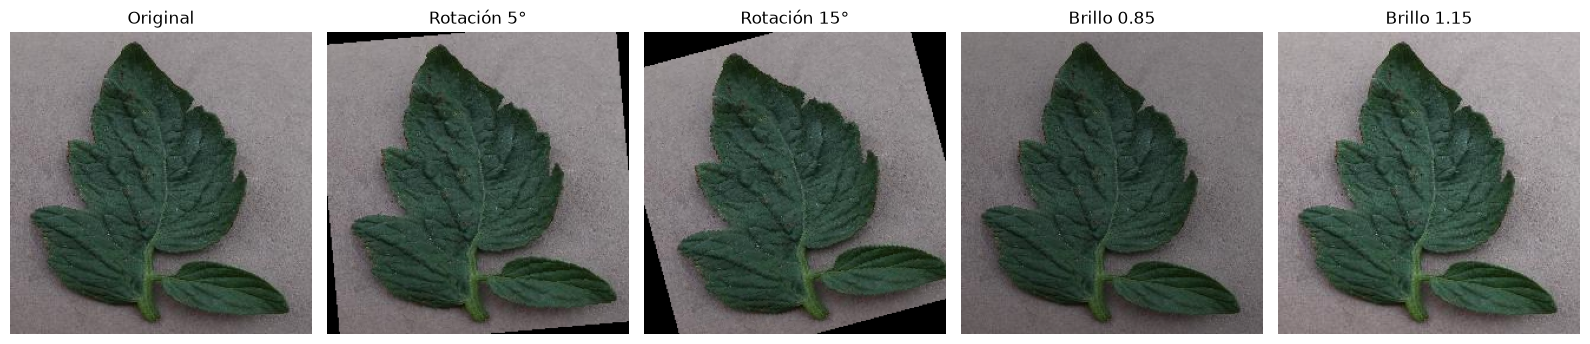

In [19]:
original_image = (train_data[0]["image"].convert("RGB"))

experiments = {
    "Original": original_image,
    "Rotación 5°": transforms.functional.rotate(original_image, 5),
    "Rotación 15°": transforms.functional.rotate(original_image, 15),
    "Brillo 0.85": transforms.functional.adjust_brightness(original_image, 0.85),
    "Brillo 1.15": transforms.functional.adjust_brightness(original_image, 1.15)
}

fig, axes = plt.subplots(1, len(experiments), figsize=(16, 4))

for ax, (name, image) in zip(axes, experiments.items()):
    ax.imshow(image)
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Transformaciones de entrenamiento

In [20]:
train_transform = transforms.Compose([
    transforms.Resize(RESIZE_SIZE, interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.85, 1.0), ratio=(0.9, 1.1),
        interpolation=transforms.InterpolationMode.BILINEAR
    ),

    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

### Transformaciones de validación y prueba

In [21]:
eval_transform = transforms.Compose([
    transforms.Resize(RESIZE_SIZE, interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

### Construcción del Dataset y los DataLoaders

In [22]:
class PlantVillageDataset(Dataset):

    def __init__(self, data, transform):
        self.data = data
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        sample = self.data[index]
        image = sample["image"].convert("RGB")
        original_label = sample["class_idx"]
        label = label_mapping[original_label]
        image = self.transform(image)

        return image, label

### Crear los tres datasets

In [24]:
train_dataset = PlantVillageDataset(train_data, train_transform)
val_dataset = PlantVillageDataset(val_data, eval_transform)
test_dataset = PlantVillageDataset(test_data, eval_transform)

### Crear los DataLoaders

In [25]:
def make_train_loader(seed):
    generator = torch.Generator()
    generator.manual_seed(seed)

    return DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        generator=generator
    )


val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

### Verificar los tensores

In [27]:
train_loader = make_train_loader(SEED)

images, labels = next(iter(train_loader))

print("Imágenes:", images.shape)
print("Etiquetas:", labels.shape)

print("Tipo de dato:", images.dtype)
print("Valor mínimo:", images.min().item())
print("Valor máximo:", images.max().item())

assert images.ndim == 4
assert images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
assert labels.min().item() >= 0
assert labels.max().item() < num_classes

Imágenes: torch.Size([32, 3, 224, 224])
Etiquetas: torch.Size([32])
Tipo de dato: torch.float32
Valor mínimo: -2.1179039478302
Valor máximo: 2.552854299545288


## Arquitectura ResNet18 y transferencia de aprendizaje

In [29]:
WEIGHTS = ResNet18_Weights.IMAGENET1K_V1
base_model = models.resnet18(weights=WEIGHTS)
print(base_model.fc)

Linear(in_features=512, out_features=1000, bias=True)


### Adaptar el clasificador 

In [30]:
num_features = base_model.fc.in_features
base_model.fc = nn.Linear(in_features=num_features, out_features=num_classes)

print(base_model.fc)

Linear(in_features=512, out_features=10, bias=True)


### Verificar las dimensiones de salida

In [32]:
base_model = base_model.to(device)
base_model.eval()

with torch.inference_mode():
    sample = images[:2].to(device)
    outputs = base_model(sample)

print("Entrada:", sample.shape)
print("Salida:", outputs.shape)

assert outputs.shape == (2, num_classes)

Entrada: torch.Size([2, 3, 224, 224])
Salida: torch.Size([2, 10])


## Diseño de los experimentos de transferencia de aprendizaje

### Definir las dos configuraciones

| Elemento | A. Backbone congelado | B. Fine-tuning parcial |
|---|---|---|
| Arquitectura | ResNet18 | ResNet18 |
| Pesos iniciales | ImageNet | ImageNet |
| layer1 | Congelada | Congelada |
| layer2 | Congelada | Congelada |
| layer3 | Congelada | Congelada |
| layer4 | Congelada | Entrenable |
| fc | Entrenable | Entrenable |
| Dataset | PlantVillage tomate | PlantVillage tomate |
| Épocas | 8 | 8 |

Las dos configuraciones partirán del mismo estado inicial incluido el clasificador recién inicializado

Esto evita que la configuración B tenga ventaja por haber recibido más épocas de entrenamiento

### Conservar el estado inicial

In [33]:
initial_state = copy.deepcopy(base_model.state_dict())

### Crear el modelo según la estrategia

In [34]:
def create_model(strategy):
    net = models.resnet18(weights=None)
    net.fc = nn.Linear(net.fc.in_features, num_classes)
    net.load_state_dict(initial_state)

    # Congelar todos los parámetros
    for parameter in net.parameters():
        parameter.requires_grad = False

    # El clasificador siempre es entrenable
    for parameter in net.fc.parameters():
        parameter.requires_grad = True

    if strategy == "finetuning":
        # Descongelar el último bloque
        for parameter in net.layer4.parameters():
            parameter.requires_grad = True
    return net.to(device)

### Construir los modelos

In [35]:
model_a = create_model("frozen")
model_b = create_model("finetuning")

### Verificar los parámetros entrenables

In [37]:
def count_parameters(net):

    total = sum(p.numel() for p in net.parameters())
    trainable = sum(p.numel() for p in net.parameters() if p.requires_grad)

    return {
        "total": total,
        "trainable": trainable,
        "percentage": 100 * trainable / total
    }

params_a = count_parameters(model_a)
params_b = count_parameters(model_b)

display(
    pd.DataFrame([
        {"configuration": "A", **params_a},
        {"configuration": "B", **params_b}
    ])
)

,configuration,total,trainable,percentage
0,A,11181642,5130,0.045879
1,B,11181642,8398858,75.112922


## Función de pérdida e hiperparámetros

In [38]:
criterion = nn.CrossEntropyLoss()

EPOCHS = 8
LR_CLASSIFIER = 1e-3
LR_BACKBONE = 1e-4
WEIGHT_DECAY = 1e-4

### Configurar Adam

In [39]:
optimizer_a = torch.optim.AdamW(
    model_a.fc.parameters(),
    lr=LR_CLASSIFIER,
    weight_decay=WEIGHT_DECAY
)

In [40]:
optimizer_b = torch.optim.AdamW(
    [
        {
            "params": model_b.layer4.parameters(),
            "lr": LR_BACKBONE
        },
        {
            "params": model_b.fc.parameters(),
            "lr": LR_CLASSIFIER
        }
    ],
    weight_decay=WEIGHT_DECAY
)

## Implementación del entrenamiento

### Implementar un epoch

In [41]:
def run_epoch(net, loader, criterion, optimizer=None, strategy="frozen"):

    training = optimizer is not None
    if training:
        # Mantener los bloques congelados en modo evaluación.
        net.eval()
        # Entrenar el clasificador.
        net.fc.train()
        # En B también entrenamos layer4.
        if strategy == "finetuning":
            net.layer4.train()
    else:
        net.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    context = (torch.enable_grad() if training else torch.inference_mode())

    with context:
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            if training:
                optimizer.zero_grad()

            logits = net(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

            predictions = logits.argmax(dim=1)
            batch_size = labels.size(0)
            total_loss += (loss.item() * batch_size)
            total_correct += (predictions == labels).sum().item()
            total_samples += batch_size
    return {
        "loss": total_loss / total_samples,
        "accuracy": total_correct / total_samples
    }

### Implementar el entrenamiento completo

In [42]:
def train_model(net, train_loader, val_loader, criterion, optimizer, epochs, strategy):

    history = []

    best_val_loss = float("inf")
    best_weights = copy.deepcopy(net.state_dict())

    for epoch in range(epochs):
        train_metrics = run_epoch(
            net=net,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            strategy=strategy
        )

        val_metrics = run_epoch(net=net, loader=val_loader, criterion=criterion)

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_metrics["loss"],
            "val_loss": val_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_accuracy": val_metrics["accuracy"]
        })

        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            best_weights = copy.deepcopy(net.state_dict())

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_metrics['loss']:.4f} | "
            f"Val Loss: {val_metrics['loss']:.4f} | "
            f"Train Acc: {train_metrics['accuracy']:.4f} | "
            f"Val Acc: {val_metrics['accuracy']:.4f}"
        )

    # Recuperar los mejores pesos encontrados.
    net.load_state_dict(best_weights)
    return net, pd.DataFrame(history)

### Entrenar la configuración A

In [43]:
set_seed(SEED)
train_loader_a = make_train_loader(SEED)

model_a, history_a = train_model(
    net=model_a,
    train_loader=train_loader_a,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_a,
    epochs=EPOCHS,
    strategy="frozen"
)

Epoch 1/8 | Train Loss: 0.8733 | Val Loss: 0.6106 | Train Acc: 0.7483 | Val Acc: 0.8112
Epoch 2/8 | Train Loss: 0.4531 | Val Loss: 0.5533 | Train Acc: 0.8688 | Val Acc: 0.8216
Epoch 3/8 | Train Loss: 0.3674 | Val Loss: 0.5656 | Train Acc: 0.8905 | Val Acc: 0.8116
Epoch 4/8 | Train Loss: 0.3195 | Val Loss: 0.5085 | Train Acc: 0.9023 | Val Acc: 0.8322
Epoch 5/8 | Train Loss: 0.2990 | Val Loss: 0.5126 | Train Acc: 0.9091 | Val Acc: 0.8285
Epoch 6/8 | Train Loss: 0.2752 | Val Loss: 0.4424 | Train Acc: 0.9127 | Val Acc: 0.8557
Epoch 7/8 | Train Loss: 0.2640 | Val Loss: 0.4486 | Train Acc: 0.9162 | Val Acc: 0.8484
Epoch 8/8 | Train Loss: 0.2478 | Val Loss: 0.4615 | Train Acc: 0.9207 | Val Acc: 0.8495


### Entrenar la configuración B

In [44]:
set_seed(SEED)
train_loader_b = make_train_loader(SEED)

model_b, history_b = train_model(
    net=model_b,
    train_loader=train_loader_b,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_b,
    epochs=EPOCHS,
    strategy="finetuning"
)

Epoch 1/8 | Train Loss: 0.2841 | Val Loss: 0.2582 | Train Acc: 0.9119 | Val Acc: 0.9204
Epoch 2/8 | Train Loss: 0.0862 | Val Loss: 0.2660 | Train Acc: 0.9723 | Val Acc: 0.9239
Epoch 3/8 | Train Loss: 0.0643 | Val Loss: 0.2522 | Train Acc: 0.9770 | Val Acc: 0.9232
Epoch 4/8 | Train Loss: 0.0414 | Val Loss: 0.1473 | Train Acc: 0.9860 | Val Acc: 0.9552
Epoch 5/8 | Train Loss: 0.0440 | Val Loss: 0.1374 | Train Acc: 0.9848 | Val Acc: 0.9573
Epoch 6/8 | Train Loss: 0.0363 | Val Loss: 0.2250 | Train Acc: 0.9876 | Val Acc: 0.9418
Epoch 7/8 | Train Loss: 0.0289 | Val Loss: 0.3004 | Train Acc: 0.9895 | Val Acc: 0.9304
Epoch 8/8 | Train Loss: 0.0267 | Val Loss: 0.3857 | Train Acc: 0.9909 | Val Acc: 0.9115


## Curvas de aprendizaje

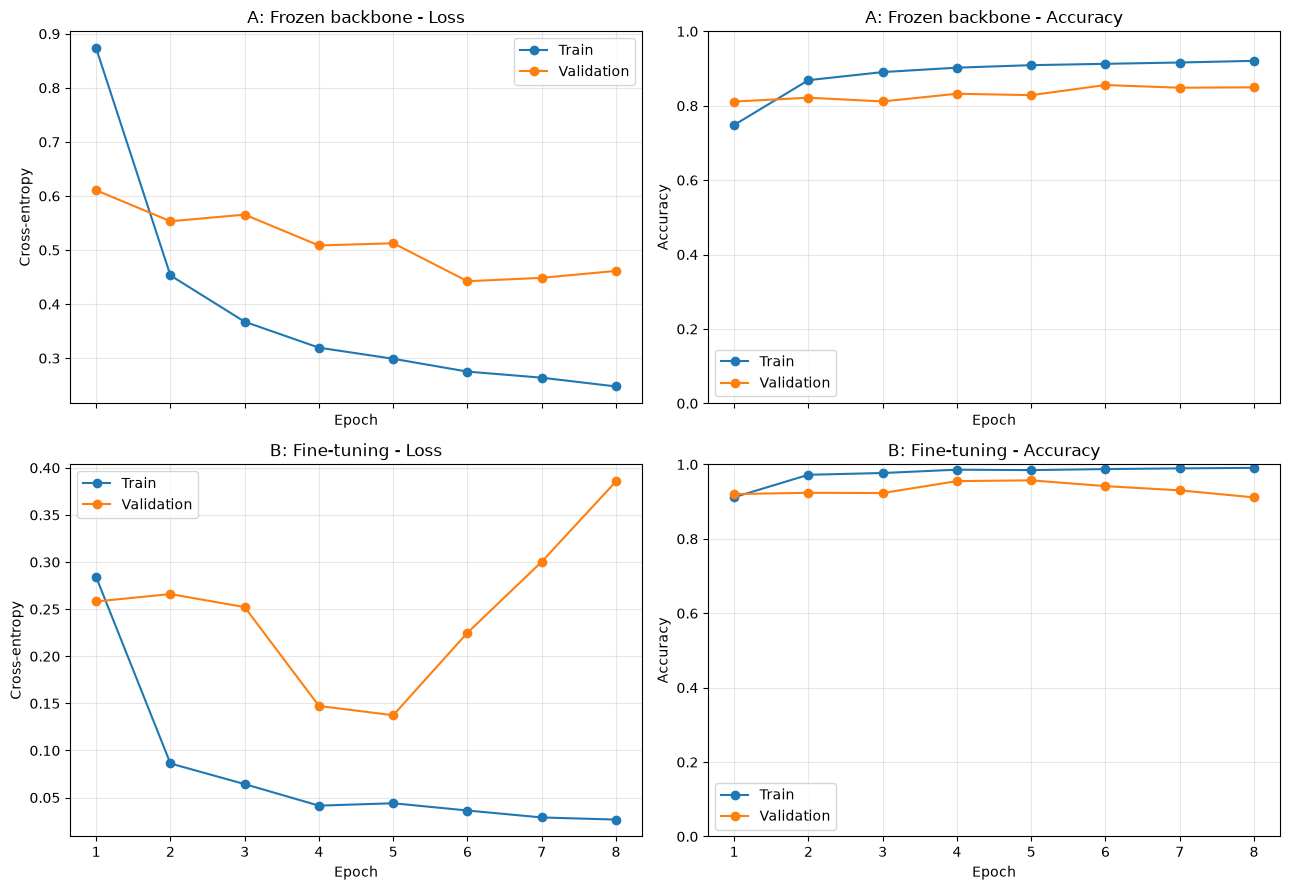

In [45]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)

histories = [
    (history_a, "A: Frozen backbone"),
    (history_b, "B: Fine-tuning")
]

for row, (history, title) in enumerate(histories):
    axes[row, 0].plot(
        history["epoch"],
        history["train_loss"],
        marker="o",
        label="Train"
    )

    axes[row, 0].plot(
        history["epoch"],
        history["val_loss"],
        marker="o",
        label="Validation"
    )

    axes[row, 0].set_title(f"{title} - Loss")
    axes[row, 0].set_ylabel("Cross-entropy")
    axes[row, 0].legend()

    axes[row, 1].plot(
        history["epoch"],
        history["train_accuracy"],
        marker="o",
        label="Train"
    )

    axes[row, 1].plot(
        history["epoch"],
        history["val_accuracy"],
        marker="o",
        label="Validation"
    )

    axes[row, 1].set_title(f"{title} - Accuracy")
    axes[row, 1].set_ylabel("Accuracy")
    axes[row, 1].set_ylim(0, 1)
    axes[row, 1].legend()

for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

La configuración A (backbone congelado) presenta una reducción más estable de la pérdida de validación, aunque alcanza una precisión inferior. Al contrario la configuración B (fine-tuning parcial) logra mejores resultados con una precisión de validación cercana al 95 % y una pérdida mínima en la quinta época. Pero a partir de ese punto, la pérdida de validación aumenta mientras la de entrenamiento continúa disminuyendo, lo que evidencia sobreajuste y una pérdida de capacidad de generalización.  

Aunque ocho épocas permiten evaluar ambas configuraciones en B el mejor desempeño se alcanza antes de finalizar las 8 épocas.

## Comparación cuantitativa de los modelos

In [46]:
results = []

for name, net, params in [
    ("Frozen backbone", model_a, params_a),
    ("Fine-tuning", model_b, params_b)
]:

    metrics = run_epoch(net=net, loader=val_loader, criterion=criterion)

    results.append({
        "configuration": name,
        "val_loss": metrics["loss"],
        "val_accuracy": metrics["accuracy"],
        "trainable_parameters": params["trainable"]
    })

df_comparison = pd.DataFrame(results)

display(df_comparison)

,configuration,val_loss,val_accuracy,trainable_parameters
0,Frozen backbone,0.442392,0.855667,5130
1,Fine-tuning,0.137414,0.957286,8398858


### Calcular las diferencias

In [48]:
delta_accuracy = (df_comparison.loc[1, "val_accuracy"] - df_comparison.loc[0, "val_accuracy"])
delta_loss = (df_comparison.loc[1, "val_loss"] - df_comparison.loc[0, "val_loss"])

print("Diferencia de accuracy:", delta_accuracy)
print("Diferencia de pérdida:", delta_loss)

Diferencia de accuracy: 0.10161901481226321
Diferencia de pérdida: -0.3049778379214363


### Seleccionar la configuración final

In [ ]:
best_index = df_comparison["val_loss"].idxmin()
best_configuration = df_comparison.loc[best_index, "configuration"]

if best_configuration == "Frozen backbone":
    final_model = model_a
else:
    final_model = model_b

print("Modelo seleccionado:", best_configuration)

Modelo seleccionado: Fine-tuning


Se elige la configuración B (fine-tuning parcial) porque consigue mejores resultados con una pérdida de validación de 0.1374 frente a 0.4424 y una precisión del 95.73 % frente al 85.57 % de la configuración A. Aunque necesita entrenar muchos más parámetros (8.4 millones frente a 5,130) y requiere más recursos, la mejora de aproximadamente 10 puntos porcentuales en precisión hace que valga la pena. Al revisar las curvas se observa que B aprende más rápido pero empieza a presentar sobreajuste después de la quinta época. Por eso lo más conveniente es quedarse con el modelo de esa época y utilizar early stopping para evitar seguir entrenando cuando el rendimiento en validación comienza a empeorar

## Evaluación del desempeño multiclase

In [50]:
def predict_dataset(net, loader):

    net.eval()

    all_true = []
    all_pred = []
    all_confidence = []

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device)
            logits = net(images)
            probabilities = torch.softmax(logits, dim=1)
            confidence, predictions = (probabilities.max(dim=1))
            all_true.extend(labels.numpy().tolist())
            all_pred.extend(predictions.cpu().numpy().tolist())
            all_confidence.extend(confidence.cpu().numpy().tolist())
    return (
        np.array(all_true),
        np.array(all_pred),
        np.array(all_confidence)
    )

### Evaluar sobre conjunto test

In [51]:
y_true, y_pred, confidences = predict_dataset(final_model, test_loader)
test_accuracy = accuracy_score(y_true, y_pred)
test_macro_f1 = f1_score(y_true, y_pred, average="macro")

print("Test accuracy:", test_accuracy)
print("Test Macro F1:", test_macro_f1)

Test accuracy: 0.9665294924554184
Test Macro F1: 0.9579473757526152


In [52]:
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

df_report = pd.DataFrame(report).T

display(
    df_report[
        ["precision", "recall", "f1-score", "support"]
    ].round(4)
)

,precision,recall,f1-score,support
Tomato___Bacterial_spot,0.9929,0.9882,0.9905,424.0000
Tomato___Early_blight,0.8761,0.9550,0.9139,200.0000
Tomato___Late_blight,0.9657,0.9581,0.9619,382.0000
Tomato___Leaf_Mold,0.9786,0.9531,0.9657,192.0000
Tomato___Septoria_leaf_spot,0.9831,0.9722,0.9777,360.0000
Tomato___Spider_mites Two-spotted_spider_mite,0.9932,0.8750,0.9304,336.0000
Tomato___Target_Spot,0.8863,0.9431,0.9138,281.0000
Tomato___Tomato_Yellow_Leaf_Curl_Virus,0.9991,0.9897,0.9944,1069.0000
Tomato___Tomato_mosaic_virus,1.0000,0.9600,0.9796,75.0000
Tomato___healthy,0.9104,0.9969,0.9517,326.0000


Las tres clases con menor F1-score son Target Spot (0.9138), Early Blight (0.9139) y Spider Mites (0.9304). En Target Spot y Early Blight el problema es la precisión (88.63 % y 87.61 %) lo que indica que el modelo confunde otras enfermedades con estas clases y genera más falsos positivos. En cambio, Spider Mites presenta una precisión muy alta (99.32 %) pero un recall menor (87.50 %) lo que significa que el modelo identifica correctamente los casos que predice como Spider Mites pero deja escapar algunos casos reales   

En cuanto al desempeño general el accuracy alcanza el 96.65 % y el Macro F1 el 95.79 %. Ambas métricas muestran resultados positivos y bastante consistentes. Pero el Macro F1 es ligeramente inferior porque da el mismo peso a todas las clases, independientemente de cuántas imágenes tengan

## Matriz de confusión y análisis de errores

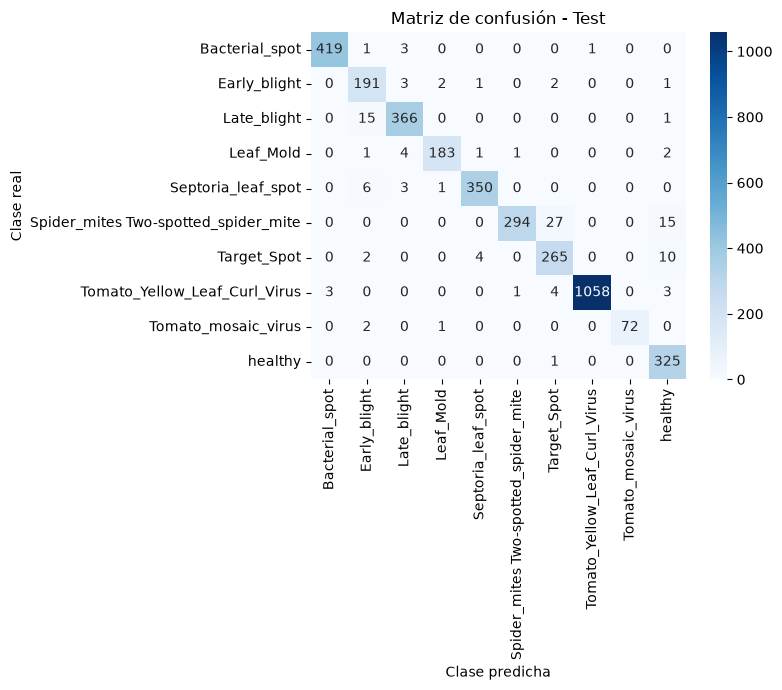

In [68]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))

clean_class_names = [name.replace("Tomato___", "") for name in class_names]

plt.figure(figsize=(8, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=clean_class_names,
    yticklabels=clean_class_names
)

plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.title("Matriz de confusión - Test")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [59]:
cm_errors = cm.copy()

np.fill_diagonal(cm_errors,0)

errors = []

for true_class in range(num_classes):
    for predicted_class in range(num_classes):
        count = cm_errors[true_class, predicted_class]

        if count > 0:
            errors.append({
                "true_class": class_names[true_class],
                "predicted_class": class_names[predicted_class],
                "errors": count
            })

df_errors = pd.DataFrame(errors)

if not df_errors.empty:
    df_errors = df_errors.sort_values("errors", ascending=False)
    display(df_errors.head(5))

,true_class,predicted_class,errors
18,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___Target_Spot,27
19,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___healthy,15
8,Tomato___Late_blight,Tomato___Early_blight,15
22,Tomato___Target_Spot,Tomato___healthy,10
15,Tomato___Septoria_leaf_spot,Tomato___Early_blight,6


### Examinar errores visuales

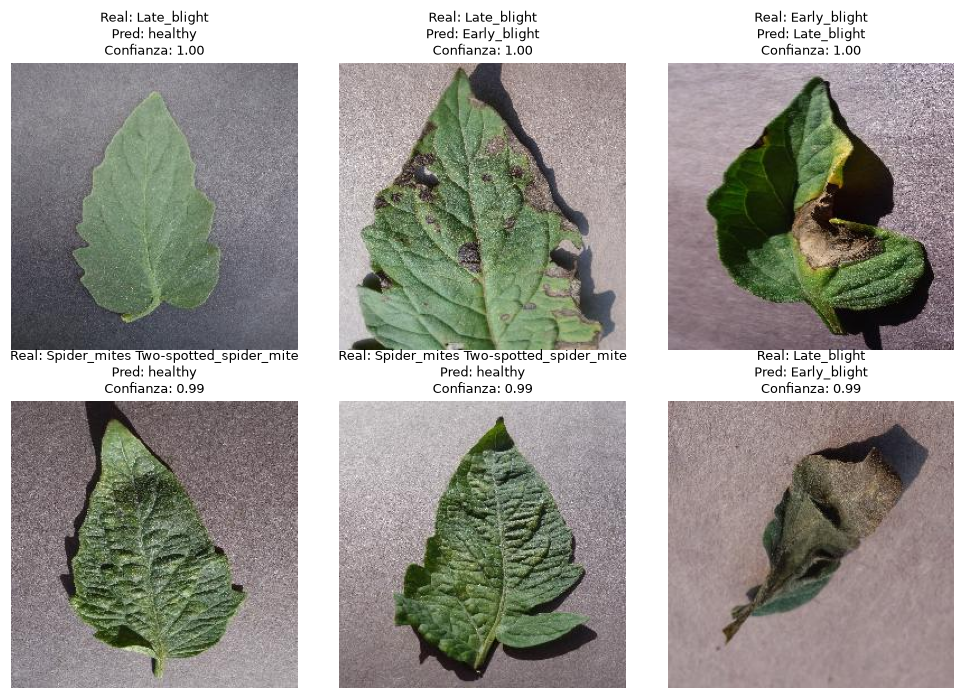

In [71]:
error_indices = np.where(y_true != y_pred)[0]
sorted_errors = sorted(error_indices, key=lambda i: confidences[i], reverse=True)
selected_errors = sorted_errors[:6]

if len(selected_errors) == 0:
    print("No se encontraron errores.")

else:
    fig, axes = plt.subplots(2, 3, figsize=(10, 7))
    axes = axes.flatten()

    for ax, index in zip(axes, selected_errors):
        image = test_data[int(index)]["image"]
        ax.imshow(image)

        real_label = class_names[y_true[index]].replace("Tomato___", "")
        pred_label = class_names[y_pred[index]].replace("Tomato___", "")

        ax.set_title(
            f"Real: {real_label}\n"
            f"Pred: {pred_label}\n"
            f"Confianza: {confidences[index]:.2f}",
            fontsize=9
        )
        ax.axis("off")

    for ax in axes[len(selected_errors):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

Aunque el modelo alcanza una accuracy del 96.65 % estos errores muestran que todavía tiene dificultades para distinguir enfermedades con características visuales similares o síntomas poco evidentes

## Guardado del modelo

In [63]:
checkpoint = {
    "model_state_dict": final_model.state_dict(),
    "configuration": best_configuration,
    "architecture": "resnet18",
    "weights": "IMAGENET1K_V1",
    "num_classes": num_classes,
    "class_names": class_names,
    "image_size": IMAGE_SIZE,
    "resize_size": RESIZE_SIZE,
    "mean": MEAN,
    "std": STD,
    "seed": SEED
}

torch.save(checkpoint, "plantvillage_resnet18.pth")

### Guardar los resultados

In [64]:
history_a.to_csv("results/history_frozen.csv", index=False)
history_b.to_csv("results/history_finetuning.csv", index=False)
df_comparison.to_csv("results/model_comparison.csv",index=False)
df_report.to_csv("results/classification_report.csv")

## Conclusiones

- Utilizar ResNet18 preentrenada con ImageNet permitió aprovechar características visuales que el modelo ya había aprendido, como bordes, texturas y patrones. Esto facilitó el entrenamiento con PlantVillage, reduciendo el tiempo y los recursos necesarios en comparación con entrenar una red desde cero. Además, permitió alcanzar buenos resultados incluso manteniendo congelada gran parte de la arquitectura

- Descongelar layer4 permitió que el modelo ajustara características más específicas de las enfermedades del tomate. Esto mejoró considerablemente el desempeño, pasando de una accuracy de validación del 85.57 % al 95.73 % y reduciendo la pérdida de 0.4424 a 0.1374. Sin embargo, también aumentó el costo computacional y provocó sobreajuste después de la quinta época

- La configuración B (fine-tuning parcial) es el mejor modelo, porque obtuvo mejores resultados tanto en pérdida como en accuracy. Aunque requiere entrenar más parámetros, la mejora de aproximadamente 10 puntos porcentuales justifica el esfuerzo adicional. Conservaría los pesos de la quinta época, cuando alcanzó su mejor desempeño de validación, para evitar el sobreajuste observado posteriormente

- Las clases con menor F1-score fueron Target Spot (91.38 %), Early Blight (91.39 %) y Spider Mites (93.04 %). En las dos primeras, el problema principal fue la precisión, mientras que Spider Mites presentó dificultades de recall. La matriz de confusión mostró que Spider Mites se confundió principalmente con Target Spot (27 casos) y hojas sanas (15 casos) mientras que Late Blight se confundió con Early Blight en 15 ocasiones

- La principal limitación es que la evaluación se realizó con imágenes de PlantVillage, que generalmente tienen fondos controlados y condiciones visuales diferentes a las que se encontraría en un cultivo real. Además el conjunto de datos esta desbalanceado algunas clases tienen muchas más imágenes que otras por lo que la accuracy puede ocultar otras dificultades. También encontramos predicciones incorrectas con confianzas cercanas al 100 % para evaluar mejor su capacidad de generalización, sería necesario probarlo con fotografías tomadas en condiciones reales diferentes iluminaciones fondos y estados de las enfermedades